# EDA

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## 2. Load Cleaned Data

In [2]:
# load the cleaned csv and use parse_dates because, csv does not preserve the data types, only parquet datatype does

daily_revenue_df = pd.read_csv(
    "../data_clean/daily_revenue_clean.csv",
    parse_dates=["date"]
)

orders_df = pd.read_csv(
    "../data_clean/orders_clean.csv",
    parse_dates=["order_datetime", "order_date"]
)

calendar_df = pd.read_csv(
    "../data_clean/calendar_clean.csv",
    parse_dates=["date"]
)

weather_df = pd.read_csv(
    "../data_clean/weather_clean.csv",
    parse_dates=["date"]
)

promotions_df = pd.read_csv(
    "../data_clean/promotions_clean.csv",
    parse_dates=["start_date", "end_date"]
)

# 3. Explore Revenue Patterns

In [3]:
daily_revenue_df.sample(5)

,date,revenue,orders,average_order_value,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,...,restaurant_day_type,holiday_name,is_holiday,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
113,2024-04-23,2161.80,63,34.31,Tuesday,2,4,April,2,17,...,Quiet,NaN,False,7.4,10.2,5.1,0.0,False,Normal,False
561,2025-07-15,2016.66,55,36.67,Tuesday,2,7,July,3,29,...,Quiet,NaN,False,18.4,23.6,14.2,0.0,False,Normal,True
467,2025-04-12,5295.50,130,40.73,Saturday,6,4,April,2,15,...,Peak,NaN,False,11.0,12.3,10.1,0.4,False,Normal,False
543,2025-06-27,4570.15,114,40.09,Friday,5,6,June,2,26,...,Peak,NaN,False,15.8,20.8,11.6,0.0,False,Normal,True
552,2025-07-06,3503.97,98,35.75,Sunday,7,7,July,3,27,...,Medium,NaN,False,21.5,26.2,17.6,0.0,False,Normal,True


In [4]:
orders_df.sample(5)

,order_id,customer_id,order_datetime,order_date,order_type,meal_period,order_total,party_size
39591,O039592,C02633,2025-06-14 12:45:23,2025-06-14,Delivery,Lunch,49.84,3
43543,O043544,C00080,2025-07-30 14:52:49,2025-07-30,Delivery,Afternoon,37.18,3
21328,O021329,C02555,2024-10-14 19:55:53,2024-10-14,Takeaway,Dinner,16.00,1
18435,O018436,C00637,2024-09-07 13:14:33,2024-09-07,Delivery,Lunch,16.10,1
1736,O001737,NaN,2024-01-26 21:38:56,2024-01-26,Dine-in,Dinner,51.51,3


In [5]:
fig = px.histogram(
    orders_df,
    x="order_total",
    nbins=50,
    title="Distribution of Individual Order Values",
    labels={"order_total": "Order Value (€)"}
)

fig.show()

In [6]:
daily_revenue_df["revenue"].describe()

count     731.000000
mean     2861.610876
std      1143.703949
min       686.700000
25%      2027.300000
50%      2517.180000
75%      3611.500000
max      6734.110000
Name: revenue, dtype: float64

In [7]:
fig = px.line(
    daily_revenue_df,
    x="date",
    y="revenue",
    title="Daily Revenue — 2024–2025",
    labels={
        "date": "Date",
        "revenue": "Revenue (€)"
    }
)

fig.show()

In [8]:
fig = px.line(
    daily_revenue_df,
    x="date",
    y="orders",
    title="Daily Order Volume — 2024-2025",
    labels={
        "date": "Date",
        "orders": "Number of Orders"
    }
)

fig.show()

In [9]:
weekday_revenue = (
    daily_revenue_df
    .groupby("day_of_week", as_index=False)
    .agg(
        average_revenue=("revenue", "mean"),
        average_orders=("orders", "mean")
    )
)
fig = px.bar(
    weekday_revenue,
    x="day_of_week",
    y="average_revenue",
    title="Average Daily Revenue by Day of Week",
    color= "day_of_week",
    labels={
        "day_of_week": "Day of Week",
        "average_revenue": "Average Revenue (€)"
    }
)

fig.show()

In [10]:
# ============================================================
# TOTAL HISTORICAL REVENUE
# ============================================================

total_revenue = daily_revenue_df["revenue"].sum()

print(f"Data from: {daily_revenue_df['date'].min().date()}")
print(f"Data to:   {daily_revenue_df['date'].max().date()}")
print(f"Number of days: {daily_revenue_df['date'].nunique()}")
print(f"Total revenue: €{total_revenue:,.2f}")

Data from: 2024-01-01
Data to:   2025-12-31
Number of days: 731
Total revenue: €2,091,837.55


In [11]:
# ============================================================
# REVENUE BY YEAR
# ============================================================
revenue_by_year = ( daily_revenue_df.groupby(daily_revenue_df["date"].dt.year)["revenue"].sum().reset_index() )

print(revenue_by_year)

   date     revenue
0  2024  1016965.93
1  2025  1074871.62


In [12]:
monthly_revenue = (
    daily_revenue_df
    .assign(
        month=lambda d: d["date"].dt.month, # will not create a new column
        year=lambda d: d["date"].dt.year # will not create a new column
    )
    .groupby(["year", "month"], as_index=False)
    .agg(avg_revenue=("revenue","mean"), avg_orders=("orders","mean"))
)

fig = px.line(
    monthly_revenue,
    x="month",
    y="avg_revenue",
    color="year",
    markers=True,
    title="Monthly Revenue by Year",
    labels={
        "month": "Month",
        "revenue": "Revenue (€)",
        "year": "Year"
    }
)

fig.show()

## Weather effects in Revenue

In [13]:
# merge weather and daily_revvenue tables
revenue_weather = daily_revenue_df.merge(
    weather_df,
    on="date",
    how="left",
    suffixes=("", "_weather")
)

In [14]:
revenue_weather

,date,revenue,orders,average_order_value,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,...,precipitation_mm,is_rainy,weather_condition,is_promo_day,temperature_avg_c_weather,temp_max_c_weather,temp_min_c_weather,precipitation_mm_weather,is_rainy_weather,weather_condition_weather
0,2024-01-01,1396.3,40,34.91,Monday,1,1,January,1,1,...,1.3,True,Rain,False,3.8,7.0,1.3,1.3,True,Rain
1,2024-01-02,2118.0,56,37.82,Tuesday,2,1,January,1,1,...,0.0,False,Cold,False,1.3,3.6,-0.5,0.0,False,Cold
2,2024-01-03,1527.3,50,30.55,Wednesday,3,1,January,1,1,...,7.0,True,Rain,False,3.4,5.3,1.9,7.0,True,Rain
3,2024-01-04,2532.3,67,37.80,Thursday,4,1,January,1,1,...,1.0,True,Rain,False,5.7,6.8,4.8,1.0,True,Rain
4,2024-01-05,3420.7,91,37.59,Friday,5,1,January,1,1,...,3.3,True,Rain,False,-0.1,1.3,-1.2,3.3,True,Rain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,2025-12-27,4453.8,106,42.02,Saturday,6,12,December,4,52,...,0.0,False,Normal,False,3.1,5.6,1.0,0.0,False,Normal
727,2025-12-28,2529.4,67,37.75,Sunday,7,12,December,4,52,...,8.9,True,Rain,False,4.8,6.2,3.7,8.9,True,Rain
728,2025-12-29,1468.9,43,34.16,Monday,1,12,December,4,1,...,0.0,False,Cold,False,1.9,3.8,0.3,0.0,False,Cold
729,2025-12-30,2040.0,56,36.43,Tuesday,2,12,December,4,1,...,0.0,False,Cold,False,-0.5,1.0,-1.7,0.0,False,Cold


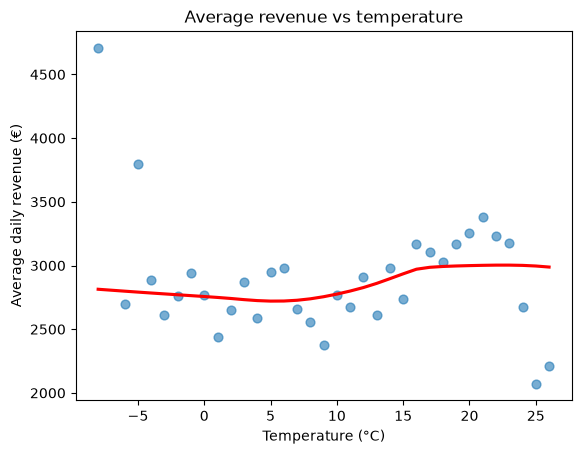

In [15]:
avg = (revenue_weather.dropna(subset=["temperature_avg_c"])
       .assign(temp=lambda d: d["temperature_avg_c"].round())      # group into whole degrees
       .groupby("temp", as_index=False)
       .agg(avg_revenue=("revenue", "mean"), days=("revenue", "size")))

sns.regplot(
    data=avg, x="temp", y="avg_revenue",
    lowess=True,
    scatter_kws={"alpha": 0.6, "s": 40}, line_kws={"color": "red"},
)
plt.title("Average revenue vs temperature")
plt.xlabel("Temperature (°C)"); plt.ylabel("Average daily revenue (€)")
plt.show()

In [16]:
plot_df = revenue_weather.dropna(subset=["temperature_avg_c"]).sort_values("temperature_avg_c")

import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=plot_df["temperature_avg_c"], y=plot_df["revenue"],
    mode="markers", name="Daily revenue",
    marker=dict(opacity=0.3, size=5),
))
# Rolling mean over sorted temperature = the "average revenue at this temp" curve
fig.add_trace(go.Scatter(
    x=plot_df["temperature_avg_c"],
    y=plot_df["revenue"].rolling(30, min_periods=5).mean(),
    mode="lines", name="Rolling avg", line=dict(color="red", width=3),
))
fig.update_layout(
    title="Revenue vs Temperature (raw + smoothed)",
    xaxis_title="Temperature (°C)", yaxis_title="Revenue (€)",
)
fig.show()

### Rain effects

In [ ]:
rain_revenue = ( revenue_weather .groupby("is_rainy", as_index=False) .agg( avg_revenue=("revenue", "mean"), avg_orders=("orders", "mean") ) )

rain_revenue

,is_rainy,avg_revenue,avg_orders
0,False,2936.870693,77.972277
1,True,2693.441814,73.946903


``` we don't need to join the weather table with daily revenue tabel as it has already all the required columns```

In [18]:
daily_revenue_df.groupby("is_rainy", as_index=False).agg(avg_revenue=("revenue", "mean"),
        avg_orders=("orders", "mean"))

,is_rainy,avg_revenue,avg_orders
0,False,2936.870693,77.972277
1,True,2693.441814,73.946903


In [19]:
daily_revenue_df.columns

Index(['date', 'revenue', 'orders', 'average_order_value', 'day_of_week',
       'day_of_week_num', 'month', 'month_name', 'quarter', 'week_of_year',
       'is_weekend', 'restaurant_peak_day', 'restaurant_day_type',
       'holiday_name', 'is_holiday', 'temperature_avg_c', 'temp_max_c',
       'temp_min_c', 'precipitation_mm', 'is_rainy', 'weather_condition',
       'is_promo_day'],
      dtype='str')

In [20]:
rain_avg = (
    daily_revenue_df
    .groupby("is_rainy", as_index=False)
    .agg(avg_revenue=("revenue", "mean"))
)

fig = px.bar(
    rain_avg,
    x="is_rainy",
    y="avg_revenue",
    title="Average Revenue: Rainy vs Dry Days",
    color='is_rainy',
    labels={
        "is_rainy": "Rainy",
        "avg_revenue": "Revenue (€)",
   
    }
)

fig.show()

In [21]:
# merge calendar and daily_revenue tables
revenue_calendar = daily_revenue_df.merge(
    calendar_df,
    on="date",
    how="left",
    suffixes=("", "_calendar")
)

In [22]:
holiday_revenue = (
    revenue_calendar
    .groupby("is_holiday", as_index=False)
    .agg(
        avg_revenue=("revenue", "mean"),
        avg=("orders", "mean")
    )
)

holiday_revenue

,is_holiday,avg_revenue,avg
0,False,2861.433004,76.679831
1,True,2867.343182,78.272727


### Holiday effects

In [23]:
fig = px.bar(
    holiday_revenue,
    x="is_holiday",
    y="avg_revenue",
    title="Average Revenue: Holiday vs Non-holiday",
    color='is_holiday',
    labels={
        "is_holiday": "Holiday",
        "avg_revenue": "Revenue (€)",
   
    }
)

fig.show()

### Promotion analysis

In [24]:
promo_analysis = (
    daily_revenue_df
    .groupby("is_promo_day", as_index=False)
    .agg(
        avg_revenue=("revenue", "mean"),
        avg_orders=("orders", "mean"),
        avg_order_value=("average_order_value", "mean")
    )
)

promo_analysis

,is_promo_day,avg_revenue,avg_orders,avg_order_value
0,False,2779.136526,74.187082,36.860423
1,True,2992.926418,80.773050,36.435106


In [25]:
fig = px.bar(
    promo_analysis,
    x="is_promo_day",
    y="avg_revenue",
    title="Average Revenue: Promotion vs Non-Promotion Days",
    color='is_promo_day',
    labels={
        "is_promo_day": "Promotion Day",
        "avg_revenue": "Average Revenue (€)"
    }
)

fig.show()

### check if promotion days mis-match in daily_revenue table

In [26]:
# Make sure dates are datetime
promotions_df["start_date"] = pd.to_datetime(promotions_df["start_date"])
promotions_df["end_date"] = pd.to_datetime(promotions_df["end_date"])
daily_revenue_df["date"] = pd.to_datetime(daily_revenue_df["date"])


# Recalculate the expected promotion flag
daily_revenue_df["expected_is_promo_day"] = 0

for _, promotion in promotions_df.iterrows():

    mask = (
        (daily_revenue_df["date"] >= promotion["start_date"]) &
        (daily_revenue_df["date"] <= promotion["end_date"])
    )

    daily_revenue_df.loc[mask, "expected_is_promo_day"] = 1


# Compare with the existing flag
promo_match = (
    daily_revenue_df["is_promo_day"]
    == daily_revenue_df["expected_is_promo_day"]
)

print("Promotion dates match:", promo_match.all())

Promotion dates match: True


## Correlation 

In [27]:
corr_columns = [
    "revenue",
    "orders",
    "average_order_value",
    "temperature_avg_c",
    "temp_max_c",
    "temp_min_c",
    "precipitation_mm"
]

correlation = revenue_weather[corr_columns].corr()

correlation.round(2)

,revenue,orders,average_order_value,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm
revenue,1.00,0.98,0.67,0.12,0.13,0.10,-0.11
orders,0.98,1.00,0.50,0.14,0.15,0.13,-0.08
average_order_value,0.67,0.50,1.00,-0.01,0.01,-0.03,-0.16
temperature_avg_c,0.12,0.14,-0.01,1.00,0.99,0.99,0.03
temp_max_c,0.13,0.15,0.01,0.99,1.00,0.95,-0.02
temp_min_c,0.10,0.13,-0.03,0.99,0.95,1.00,0.07
precipitation_mm,-0.11,-0.08,-0.16,0.03,-0.02,0.07,1.00


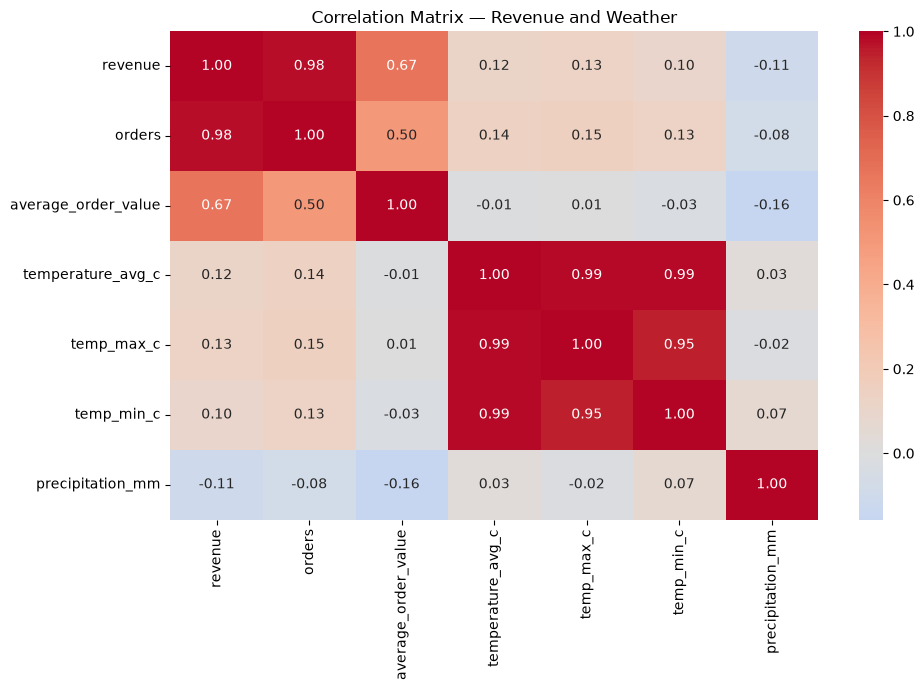

In [28]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix — Revenue and Weather")
plt.tight_layout()
plt.show()

In [29]:
daily_revenue_df["date"] = pd.to_datetime(daily_revenue_df["date"])
monthly_revenue = daily_revenue_df.resample("ME", on="date")["revenue"].sum()
monthly_revenue

date
2024-01-31     75365.31
2024-02-29     75383.20
2024-03-31     83305.33
2024-04-30     77574.30
2024-05-31     83598.20
2024-06-30     84492.30
2024-07-31     90856.22
2024-08-31     99119.55
2024-09-30     84652.20
2024-10-31     88278.67
2024-11-30     83172.00
2024-12-31     91168.65
2025-01-31     79593.92
2025-02-28     79735.40
2025-03-31     84078.27
2025-04-30     82158.47
2025-05-31     96449.30
2025-06-30     93076.41
2025-07-31     98458.20
2025-08-31    106885.67
2025-09-30     85929.60
2025-10-31     91941.74
2025-11-30     85309.10
2025-12-31     91255.54
Freq: ME, Name: revenue, dtype: float64

<Axes: xlabel='date'>

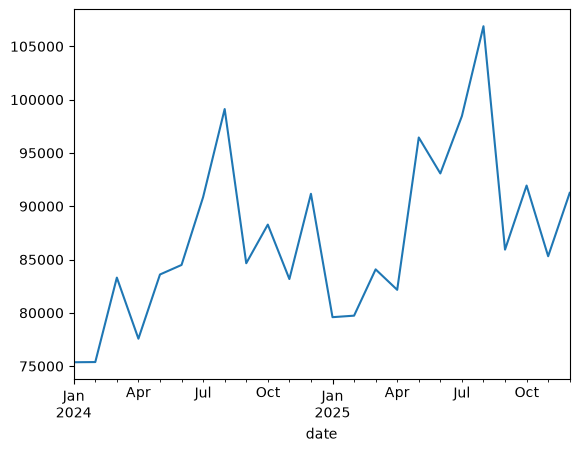

In [30]:
monthly_revenue.plot()

In [31]:
daily_revenue_df["date"] = pd.to_datetime(daily_revenue_df["date"])
weekly_revenue = daily_revenue_df.resample("W", on="date")["revenue"].sum()
weekly_revenue

date
2024-01-07    17595.00
2024-01-14    17739.23
2024-01-21    17201.67
2024-01-28    18866.01
2024-02-04    16367.30
                ...   
2025-12-07    25498.64
2025-12-14    19714.20
2025-12-21    19720.50
2025-12-28    20489.30
2026-01-04     5832.90
Freq: W-SUN, Name: revenue, Length: 105, dtype: float64

<Axes: xlabel='date'>

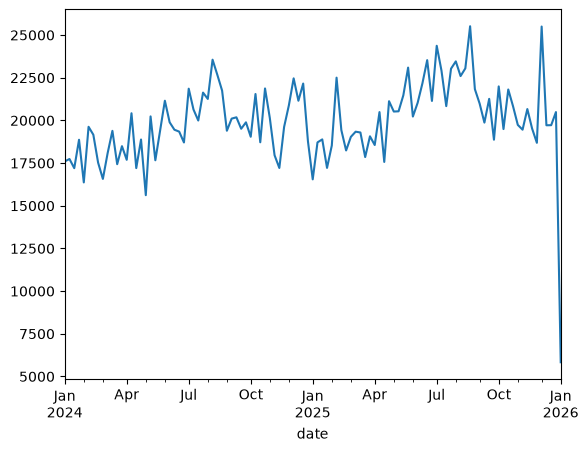

In [32]:
weekly_revenue.plot()

# 4. Final Modelling Dataset

let us merge the tables for the final forecasting

In [33]:
order_items_df = pd.read_csv("../data_clean/order_items_clean.csv")
products_df = pd.read_csv("../data_clean/products_clean.csv")

In [34]:
# Prepare order dates
orders_df["date"] = orders_df["order_datetime"].dt.normalize()

In [35]:
# Create all daily order features together
daily_order_features = (
    orders_df
    .groupby("date")
    .agg(
        orders_lunch=("meal_period", lambda x: (x == "Lunch").sum()),
        orders_afternoon=("meal_period", lambda x: (x == "Afternoon").sum()),
        orders_dinner=("meal_period", lambda x: (x == "Dinner").sum()),

        orders_dine_in=("order_type", lambda x: (x == "Dine-in").sum()),
        orders_delivery=("order_type", lambda x: (x == "Delivery").sum()),
        orders_takeaway=("order_type", lambda x: (x == "Takeaway").sum())
    )
    .reset_index()
)

In [36]:
# Connect order items to products
order_items_products = order_items_df.merge(
    products_df[["product_id", "category"]],
    on="product_id",
    how="left"
)

In [37]:
# Add the order date
order_items_products = order_items_products.merge(
    orders_df[["order_id", "date"]],
    on="order_id",
    how="left"
)

In [38]:
# 
drink_items = order_items_products[
    order_items_products["category"] == "Drink"
].copy()

In [39]:
# Calculate daily drink revenue
daily_drink_revenue = (
    order_items_products[
        order_items_products["category"] == "Drink"
    ]
    .groupby("date")["line_total"]
    .sum()
    .reset_index(name="drink_revenue")
)

In [40]:
# Build the final daily model table
daily_model_df = (
    daily_revenue_df
    .merge(
        daily_order_features,
        on="date",
        how="left"
    )
    .merge(
        daily_drink_revenue,
        on="date",
        how="left"
    )
)

In [41]:
# Replace missing daily values with zero
daily_model_df[
    [
        "orders_lunch",
        "orders_afternoon",
        "orders_dinner",
        "orders_dine_in",
        "orders_delivery",
        "orders_takeaway",
        "drink_revenue"
    ]
] = daily_model_df[
    [
        "orders_lunch",
        "orders_afternoon",
        "orders_dinner",
        "orders_dine_in",
        "orders_delivery",
        "orders_takeaway",
        "drink_revenue"
    ]
].fillna(0)

In [42]:
# Put the columns in the exact order you want
final_columns = [
    "date",
    "revenue",
    "orders",
    "average_order_value",

    "orders_lunch",
    "orders_afternoon",
    "orders_dinner",

    "orders_dine_in",
    "orders_delivery",
    "orders_takeaway",

    "drink_revenue",

    "day_of_week",
    "day_of_week_num",
    "month",
    "month_name",
    "quarter",
    "week_of_year",
    "is_weekend",
    "restaurant_peak_day",
    "restaurant_day_type",
    "holiday_name",
    "is_holiday",

    "temperature_avg_c",
    "temp_max_c",
    "temp_min_c",
    "precipitation_mm",
    "is_rainy",
    "weather_condition",
    "is_promo_day"
]

daily_model_df = daily_model_df[final_columns]

In [43]:
# Save the data_model_table
daily_model_df.to_csv(
    "../data_clean/daily_model_table_clean.csv",
    index=False
)

print("Daily model table saved successfully.")

Daily model table saved successfully.
